# Flows of goods on the transport network

Reproduces **`fig_flows_full_durations.png`** (supplementary, `fig:si_flows`): initial
equilibrium flows (blue) and end-of-disruption flows (red) for the 4/8/12-day country-scale
scenario.

**Data**: `data/scenarios/230927_simultaneous_{4d_v2,8d_v2,12d}/transport_edges_with_flows_{0,1}.geojson`
(time step 0 and final time step; 4d/8d use the v2 runs, 12d uses the original run)
and the GADM level-0 boundary in `data/reference/`.

**Environment**: `dsc` conda env.

In [1]:
from pathlib import Path

BUNDLE = Path.cwd()
MC = BUNDLE / "data" / "monte_carlo"
SCEN = BUNDLE / "data" / "scenarios"
REF = BUNDLE / "data" / "reference"
FIGDIR = BUNDLE / "figures" / "generated"
FIGDIR.mkdir(parents=True, exist_ok=True)

import contextily as ctx
ctx.tile.USER_AGENT = "DisruptSC-Cambodia-paper-figures/1.0 (research reproducibility notebooks)"

## Setup and data

In [2]:
import pandas as pd
import numpy as np
import geopandas as gpd
import matplotlib.pyplot as plt
import contextily as ctx
from matplotlib.ticker import FuncFormatter

cambodia = gpd.read_file(REF / 'gadm41_KHM_0.shp')

In [3]:
def deg_formatter(x, pos):
    return f'{x:.2f}°'

def add_basemap_with_latlon(ax, gdf_webmerc):
    try:
        ctx.add_basemap(ax, source=ctx.providers.OpenStreetMap.Mapnik, alpha=0.4)
    except Exception as e:
        print(f"Basemap error: {e}")
    
    bounds = gdf_webmerc.total_bounds
    lons = np.linspace(bounds[0], bounds[2], 5)
    lats = np.linspace(bounds[1], bounds[3], 5)
    
    lon_labels = [gpd.GeoSeries([gpd.points_from_xy([0], [lat])[0]], crs='EPSG:3857').to_crs(epsg=4326).y[0] for lat in lats]
    lat_labels = [gpd.GeoSeries([gpd.points_from_xy([lon], [0])[0]], crs='EPSG:3857').to_crs(epsg=4326).x[0] for lon in lons]
    
    ax.set_yticks(lats)
    ax.set_yticklabels([f'{y:.2f}°' for y in lon_labels])
    ax.set_xticks(lons)
    ax.set_xticklabels([f'{x:.2f}°' for x in lat_labels])
    ax.set_xlabel('Longitude')
    ax.set_ylabel('Latitude')

### Flows mapped onto the transport network

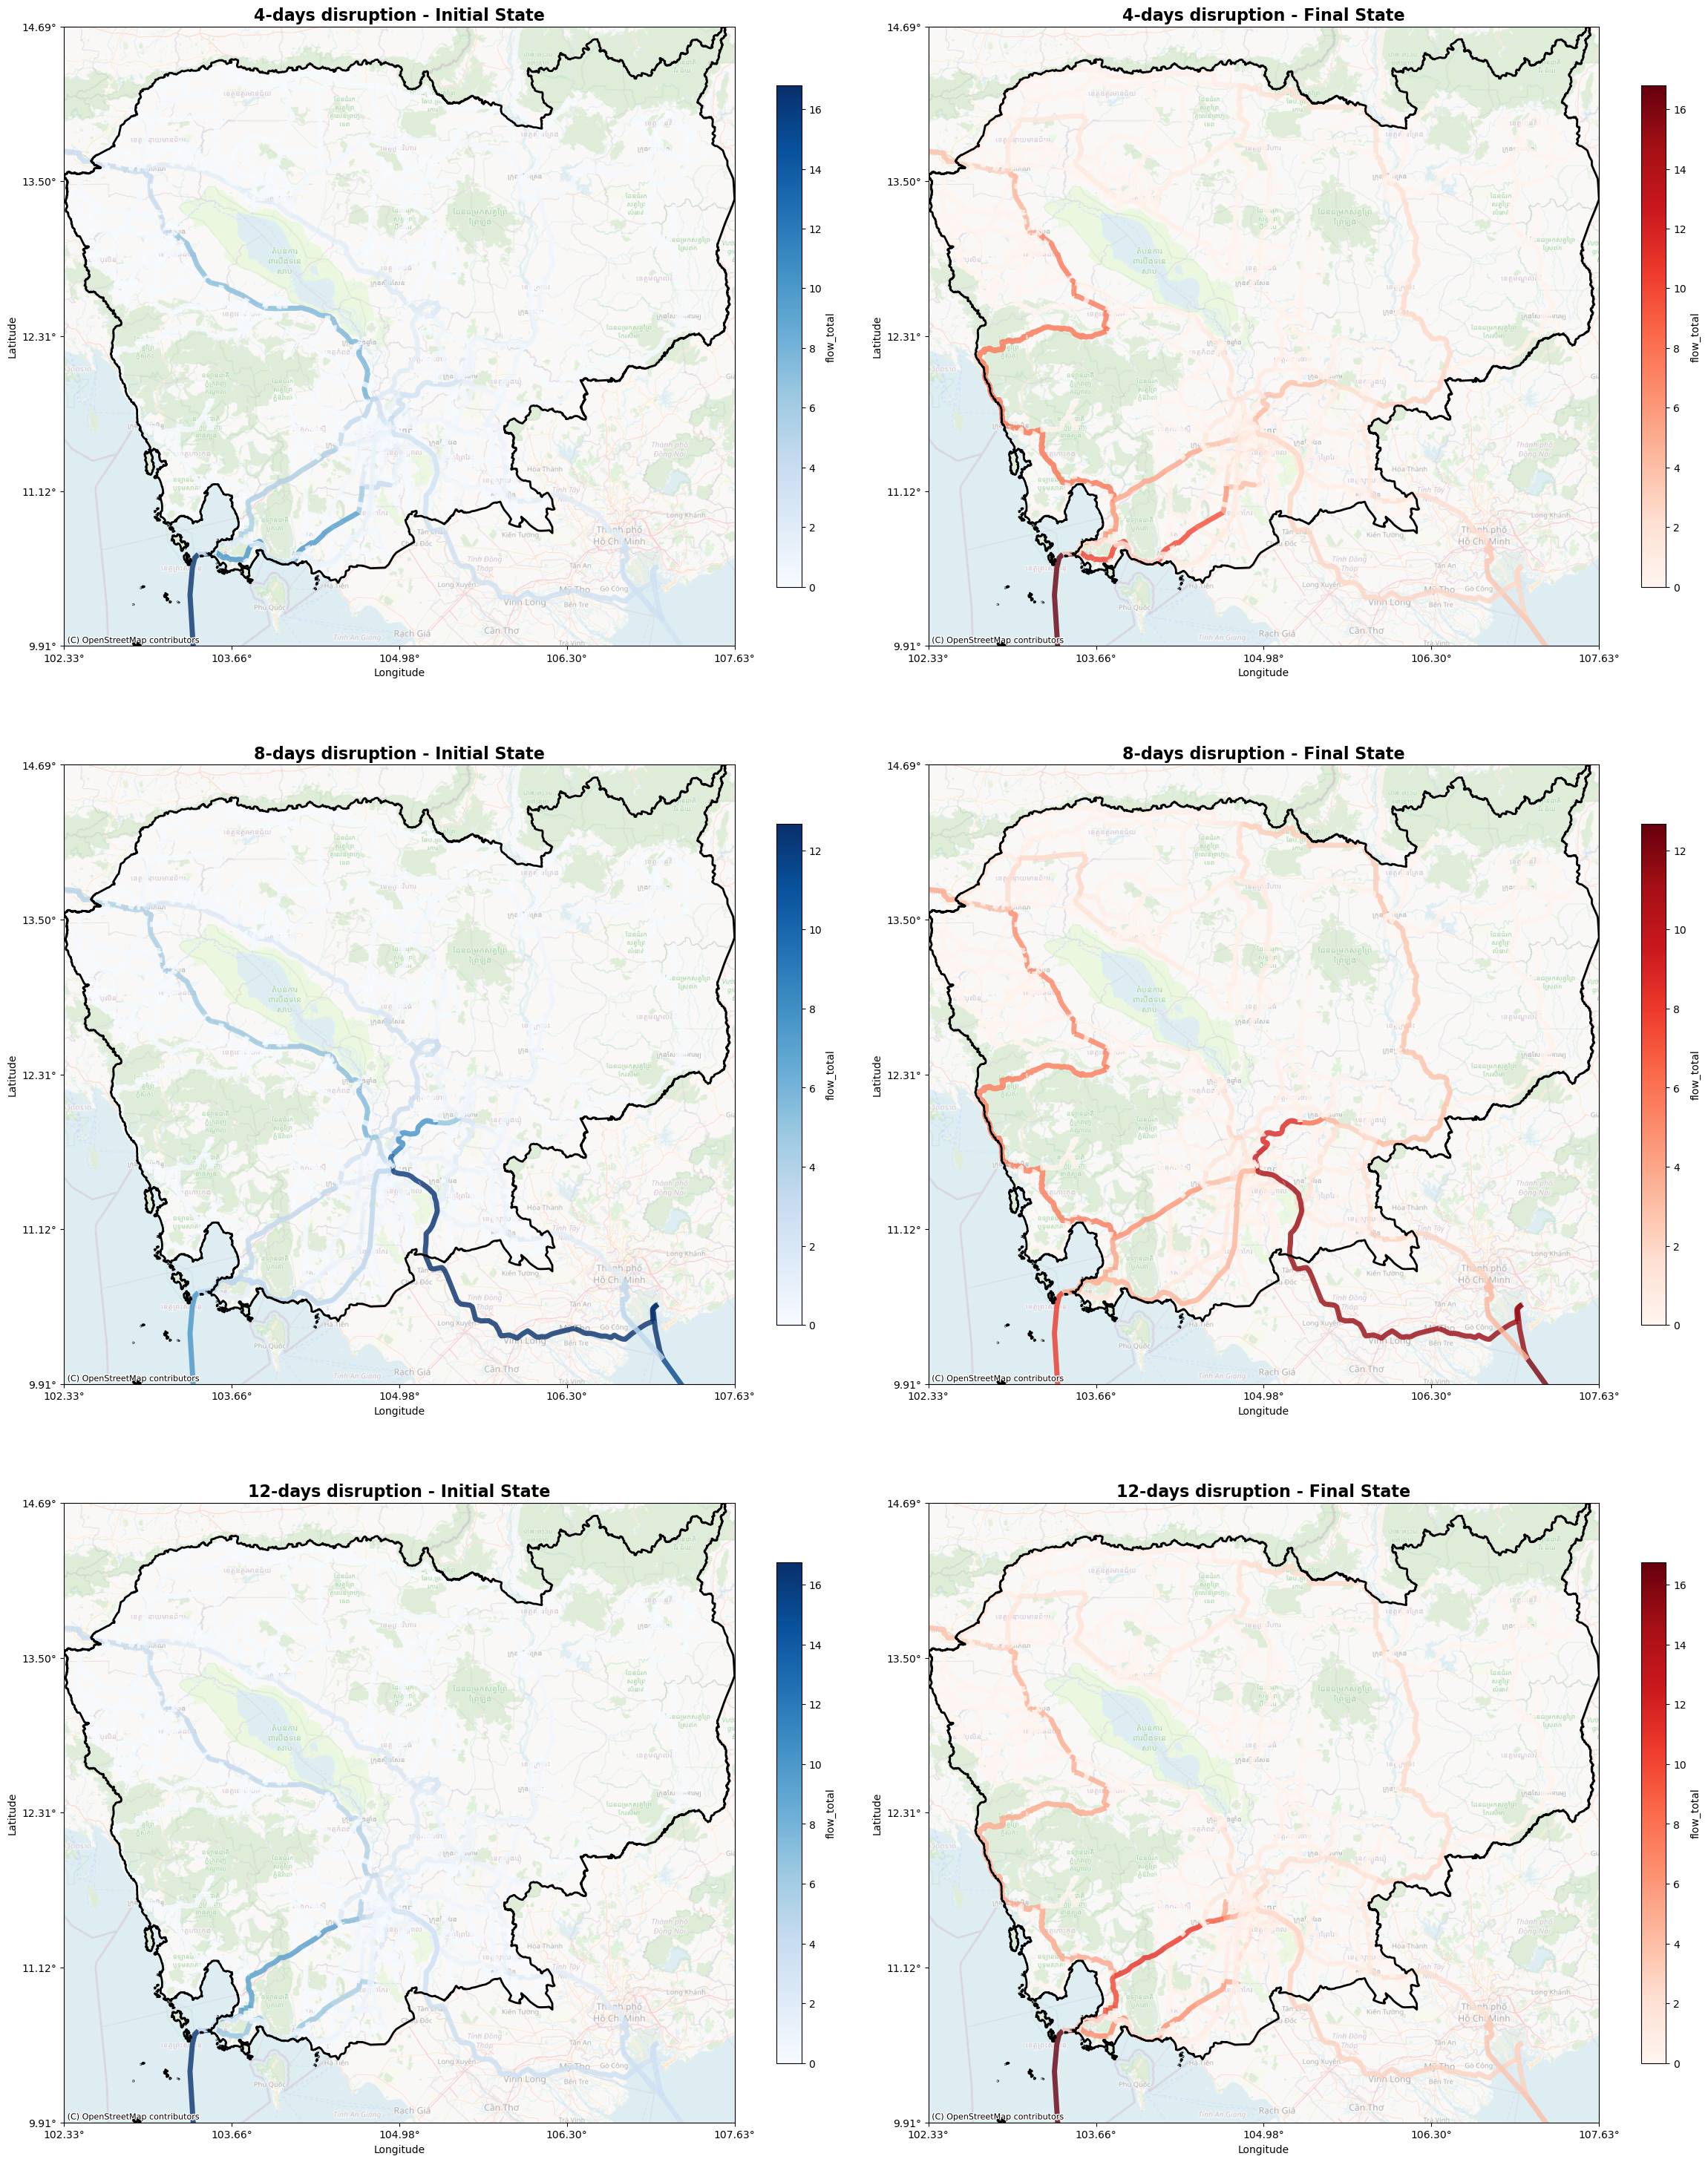

In [4]:
scenario_dirs = {'4d': '230927_simultaneous_4d_v2', '8d': '230927_simultaneous_8d_v2', '12d': '230927_simultaneous_12d'}
cambodia_webmerc = cambodia.to_crs(epsg=3857)

fig, axes = plt.subplots(3, 2, figsize=(24, 30))

for row_idx, (duration, scen_dir) in enumerate(scenario_dirs.items()):
    initial = gpd.read_file(SCEN / scen_dir / 'transport_edges_with_flows_0.geojson').to_crs(epsg=3857)
    final = gpd.read_file(SCEN / scen_dir / 'transport_edges_with_flows_1.geojson').to_crs(epsg=3857)
    
    vmax = max(initial['flow_total'].max(), final['flow_total'].max())
    
    ax_init = axes[row_idx, 0]
    cambodia_webmerc.boundary.plot(ax=ax_init, linewidth=2, edgecolor='black', zorder=5)
    initial[initial['flow_total'] > 0].plot(ax=ax_init, column='flow_total', cmap='Blues', 
                                             linewidth=5, alpha=0.8, legend=True, 
                                             legend_kwds={'label': 'flow_total', 'shrink': 0.7}, 
                                             vmin=0, vmax=vmax)
    ax_init.set_xlim(cambodia_webmerc.total_bounds[0], cambodia_webmerc.total_bounds[2])
    ax_init.set_ylim(cambodia_webmerc.total_bounds[1], cambodia_webmerc.total_bounds[3])
    add_basemap_with_latlon(ax_init, cambodia_webmerc)
    ax_init.set_title(f'{duration[:-1]}-days disruption - Initial State', fontsize=16, fontweight='bold')
    
    ax_final = axes[row_idx, 1]
    cambodia_webmerc.boundary.plot(ax=ax_final, linewidth=2, edgecolor='black', zorder=5)
    final[final['flow_total'] > 0].plot(ax=ax_final, column='flow_total', cmap='Reds', 
                                         linewidth=5, alpha=0.8, legend=True, 
                                         legend_kwds={'label': 'flow_total', 'shrink': 0.7}, 
                                         vmin=0, vmax=vmax)
    ax_final.set_xlim(cambodia_webmerc.total_bounds[0], cambodia_webmerc.total_bounds[2])
    ax_final.set_ylim(cambodia_webmerc.total_bounds[1], cambodia_webmerc.total_bounds[3])
    add_basemap_with_latlon(ax_final, cambodia_webmerc)
    ax_final.set_title(f'{duration[:-1]}-days disruption - Final State', fontsize=16, fontweight='bold')

plt.tight_layout()
plt.savefig(FIGDIR / 'fig_flows_full_durations.png', dpi=100, bbox_inches='tight')
plt.show()